In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import make_pipeline, make_union

from src.data import get_data
from src.evaluate import log_result, metrics, plot_results, show
from src.preprocess import URL_PATTERN, build_pipeline, strip_quotes
from src.train import fit_with_threshold, set_seed

set_seed(42)

c:\Users\rawi9\Desktop\BDIO\LLM\tps\New folder\Arabic-sarcasm\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
train, val, test, report = get_data()

In [14]:
for k, v in report.items():
    print(f"{k}: {v}")

start: 11293
key_exact/dup_train: 54
key_exact/dup_val: 0
key_exact/dup_test: 4
key_exact/train_in_test: 2
key_exact/test_in_train: 2
key/dup_train: 331
key/dup_val: 4
key/dup_test: 5
key/train_in_test: 2
key/test_in_train: 2
conflict_groups: 59
conflict_rows: 120
removed_in_test: 2
removed_in_val: 72
removed_conflicting: 96
removed_duplicates: 281
end: 10842


In [12]:
y_val = val["sarcasm"]
never = np.zeros(len(val), dtype=int)

print("Never sarcastic")
print("accuracy:", round(accuracy_score(y_val, never), 4))
print("F1:", round(f1_score(y_val, never, zero_division=0), 4))

Never sarcastic
accuracy: 0.8271
F1: 0.0


In [5]:
def build_model(C=1.0):
    words = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    chars = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)

    return make_pipeline(
        make_union(words, chars),
        LogisticRegression(C=C, class_weight="balanced", max_iter=1000)
    )

In [6]:
def run(combos):
    rows = []

    for name, steps in combos.items():
        prep = build_pipeline(steps)
        X_train = train["tweet"].apply(prep)
        X_val = val["tweet"].apply(prep)

        model = build_model()
        threshold, seconds = fit_with_threshold(
            model, X_train, train["sarcasm"], X_val, val["sarcasm"]
        )
        scores = metrics(val["sarcasm"], model.predict_proba(X_val)[:, 1], threshold)

        log_result(
            model="tfidf_lr",
            preprocessing=name,
            seed=42,
            threshold=threshold,
            train_time=seconds,
            trained_params=model[-1].coef_.size + 1,
            **{f"val_{k}": v for k, v in scores.items()}
        )

        show(name, scores, threshold, seconds)
        rows.append({"preprocessing": name, "threshold": threshold, **scores})

    return pd.DataFrame(rows).set_index("preprocessing")

In [17]:
BASE = ["html", "mentions", "hashtags"]
EMOJI = ["emoji"]
NORM = ["diacritics", "kashida", "letters", "elongation"]
LIGHT = ["light_stem"]

COMBOS = {
    "base": BASE,
    "emoji": BASE + EMOJI,
    "norm": BASE + NORM,
    "light_stem": BASE + LIGHT,
    "emoji + norm": BASE + EMOJI + NORM,
    "emoji + light_stem": BASE + EMOJI + LIGHT,
    "norm + light_stem": BASE + NORM + LIGHT,
    "emoji + norm + light_stem": BASE + EMOJI + NORM + LIGHT,
    "urls removed": BASE + ["remove_urls"],
    "urls replaced": BASE + ["replace_urls"],
    "quotes stripped": BASE + ["quotes"],
}

table = run(COMBOS)

base                         f1=0.5126  pr_auc=0.5210  threshold=0.41  3s
emoji                        f1=0.5298  pr_auc=0.5352  threshold=0.48  4s
norm                         f1=0.5221  pr_auc=0.5165  threshold=0.50  3s
light_stem                   f1=0.5434  pr_auc=0.5033  threshold=0.48  3s
emoji + norm                 f1=0.5397  pr_auc=0.5302  threshold=0.54  3s
emoji + light_stem           f1=0.5448  pr_auc=0.5168  threshold=0.46  3s
norm + light_stem            f1=0.5455  pr_auc=0.5211  threshold=0.49  2s
emoji + norm + light_stem    f1=0.5556  pr_auc=0.5325  threshold=0.52  2s
urls removed                 f1=0.5107  pr_auc=0.5147  threshold=0.44  3s
urls replaced                f1=0.5236  pr_auc=0.5257  threshold=0.42  3s
quotes stripped              f1=0.5150  pr_auc=0.5197  threshold=0.42  3s


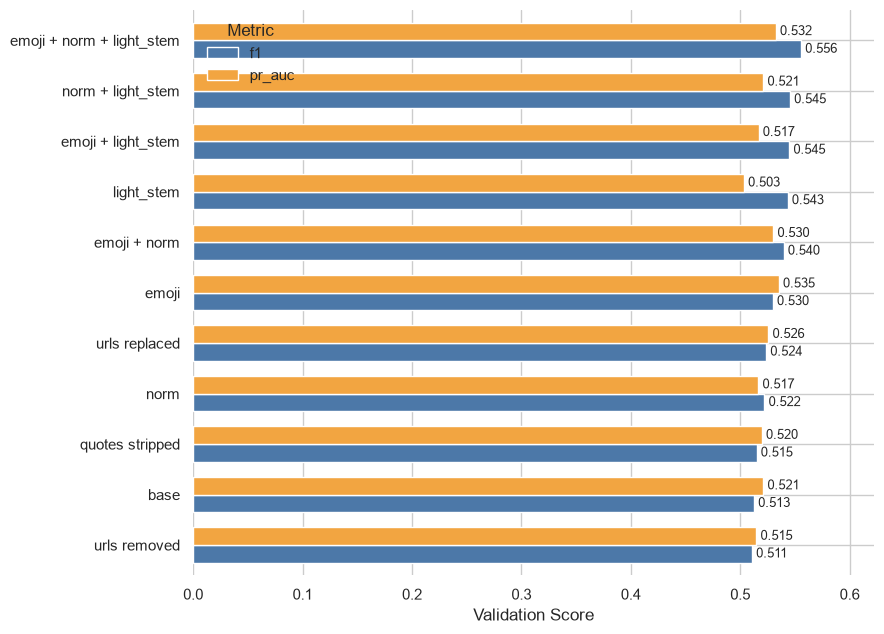

In [18]:
plot_results(table)